<a href="https://colab.research.google.com/github/Irena942/Stroke-Prediction-AI/blob/main/healthcare2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Fetch data or simulate a suitable dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

# Upload your healthcare stroke CSV file
uploaded = files.upload()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv


In [ ]:
file_name = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(file_name)

print("Dataset loaded successfully.")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully.
Number of rows and columns: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Check the dataset structure

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStroke class distribution:")
display(df["stroke"].value_counts())

Column names:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Data types:
id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

Missing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Duplicate rows: 0

Stroke class distribution:


,count
stroke,
0,4861
1,249


**2: Refinement and imputation**

This stage improves data quality by removing duplicate records and handling missing values.

In [ ]:
# Make a copy of the original data
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove the ID column if it exists
if "id" in df_clean.columns:
    df_clean = df_clean.drop(columns=["id"])

# Remove records without a known target label
df_clean = df_clean.dropna(subset=["stroke"])

# Separate features and target
X = df_clean.drop(columns=["stroke"])
y = df_clean["stroke"].astype(int)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values remaining in features:")
display(X.isnull().sum())

Original dataset shape: (5110, 12)
Cleaned dataset shape: (5110, 11)

Missing values remaining in features:


,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201
smoking_status,0


Identify numerical and categorical features

In [ ]:
# Identify numerical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

Categorical features:
['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


**3: Data processing and structural scaling**

This stage prepares the data for Logistic Regression by encoding categorical variables, scaling numerical features and separating training data from testing data.

Split the dataset

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training dataset:", X_train.shape)
print("Testing dataset:", X_test.shape)

print("\nTraining class distribution:")
display(y_train.value_counts())

Training dataset: (4088, 10)
Testing dataset: (1022, 10)

Training class distribution:


,count
stroke,
0,3889
1,199


Create the preprocessing pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical data: fill missing values and scale
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical data: fill missing values and encode
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


**4: Model training and refinement comparisons**

We will train two Logistic Regression models. The first is the baseline model. The second uses class weighting to address the imbalance between stroke and non-stroke records.

Train the initial model

In [ ]:
from sklearn.linear_model import LogisticRegression

initial_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

initial_model.fit(X_train, y_train)

initial_predictions = initial_model.predict(X_test)
initial_probabilities = initial_model.predict_proba(X_test)[:, 1]

print("Initial model trained successfully.")

Initial model trained successfully.



Train the refined model

In [ ]:
refined_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        C=0.5,
        random_state=42
    ))
])

refined_model.fit(X_train, y_train)

refined_predictions = refined_model.predict(X_test)
refined_probabilities = refined_model.predict_proba(X_test)[:, 1]

print("Refined model trained successfully.")

Refined model trained successfully.


**5: Output metrics report**

This stage calculates the evaluation metrics for both models and creates a comparison table for your report.

Calculate the performance metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

def evaluate_model(y_true, predictions, probabilities, name):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

initial_metrics = evaluate_model(
    y_test,
    initial_predictions,
    initial_probabilities,
    "Initial Model"
)

refined_metrics = evaluate_model(
    y_test,
    refined_predictions,
    refined_probabilities,
    "Refined Model"
)

results = pd.DataFrame([
    initial_metrics,
    refined_metrics
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Initial Model,0.9521,1.0000,0.02,0.0392,0.8417
1,Refined Model,0.7446,0.1375,0.80,0.2346,0.8433


Print the detailed classification report

In [ ]:
print("INITIAL MODEL")
print(classification_report(
    y_test,
    initial_predictions,
    target_names=["No Stroke", "Stroke"],
    zero_division=0
))

print("\nREFINED MODEL")
print(classification_report(
    y_test,
    refined_predictions,
    target_names=["No Stroke", "Stroke"],
    zero_division=0
))

INITIAL MODEL
              precision    recall  f1-score   support

   No Stroke       0.95      1.00      0.98       972
      Stroke       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022


REFINED MODEL
              precision    recall  f1-score   support

   No Stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.82      1022



Save the metrics report

In [ ]:
results.to_csv("model_metrics_report.csv", index=False)

print("Metrics report saved successfully.")

from google.colab import files
files.download("model_metrics_report.csv")

Metrics report saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**6: Chart generation and evaluation plots**

These plots provide visual evidence for your M3 testing and refinement.

Plot the model comparison

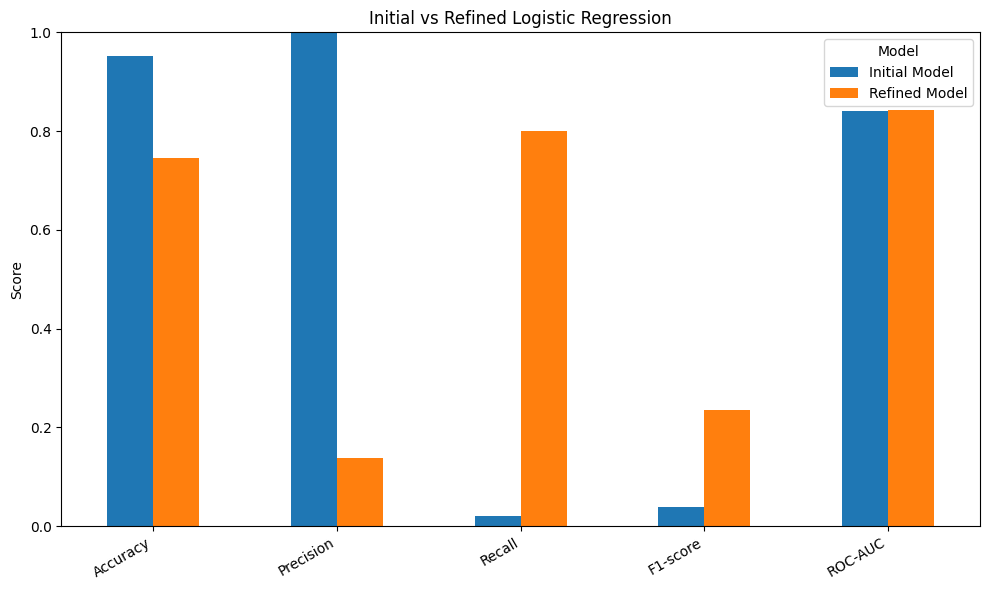

In [ ]:
comparison = results.set_index("Model")

comparison[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].T.plot(kind="bar", figsize=(10, 6))

plt.title("Initial vs Refined Logistic Regression")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

Plot the initial confusion matrix

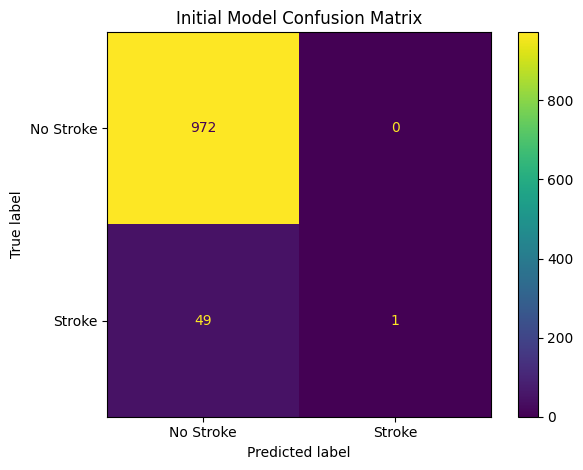

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    initial_predictions,
    display_labels=["No Stroke", "Stroke"],
    values_format="d"
)

plt.title("Initial Model Confusion Matrix")
plt.tight_layout()
plt.show()

Plot the refined confusion matrix

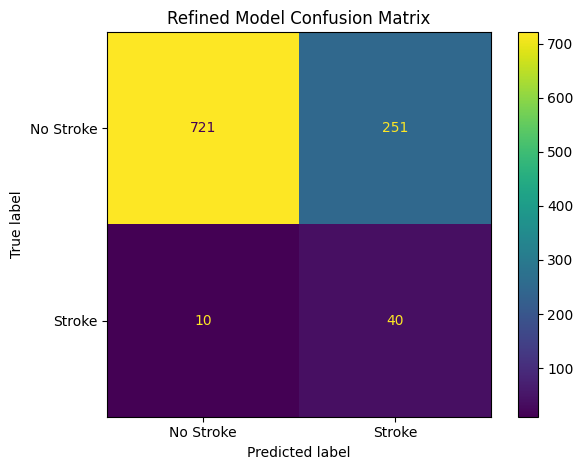

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    refined_predictions,
    display_labels=["No Stroke", "Stroke"],
    values_format="d"
)

plt.title("Refined Model Confusion Matrix")
plt.tight_layout()
plt.show()

Plot the ROC curves

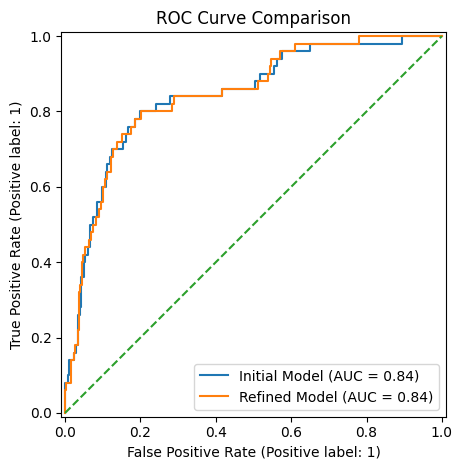

In [ ]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    initial_probabilities,
    name="Initial Model"
)

RocCurveDisplay.from_predictions(
    y_test,
    refined_probabilities,
    name="Refined Model",
    ax=plt.gca()
)

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()